# P2. Riesgo de estacion sin bicicletas o sin anclajes

Exploracion de la etiqueta de P2 y de los resultados del experimento base.
Requiere haber corrido antes:

```
python -m mibici.dataset --start-year 2025 --start-month 1 --end-year 2026 --end-month 9
python -m mibici.features_p2
python -m mibici.modeling.train_p2 --niveles 0.5 0.3 0.7
```

In [1]:
import json
import matplotlib.pyplot as plt
import pandas as pd

from mibici.config import CONFIG
from mibici import features_p2 as fp

panel = pd.read_parquet(CONFIG.interim_data_dir / "p2_panel_horario.parquet")
resumen = json.loads((CONFIG.interim_data_dir / "p2_panel_horario.json").read_text())
resumen

{'viajes_totales': 7894097,
 'viajes_sin_fecha_o_estacion': 0,
 'estaciones_en_viajes': 472,
 'estaciones_sin_nomenclatura': 2,
 'estaciones_capacidad_cero': 0,
 'viajes_que_tocan_estacion_excluida': 3954,
 'estaciones_modeladas': 470,
 'filas_panel': 5881392}

## Distribucion de clases segun el nivel inicial supuesto

In [2]:
dist = {}
for nivel in (0.3, 0.5, 0.7):
    df = fp.construir_features(fp.agregar_ocupacion(panel, nivel))
    df = df[df["ts_objetivo"] >= "2025-01-01"]
    dist[nivel] = df["objetivo"].value_counts(normalize=True)
pd.DataFrame(dist).round(3)

,0.3,0.5,0.7
objetivo,,,
segura,0.782,0.860,0.838
sin_anclajes,0.037,0.065,0.124
sin_bicicletas,0.181,0.075,0.038


## Proporcion mensual de clases (nivel inicial 50%)

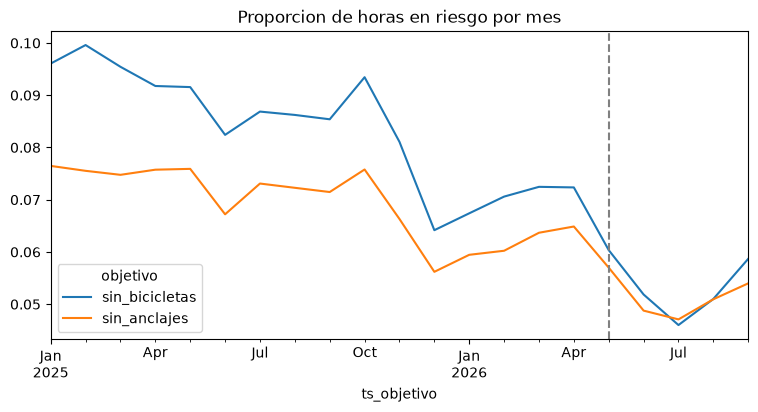

objetivo,segura,sin_anclajes,sin_bicicletas
ts_objetivo,,,
2025-01,0.827,0.076,0.096
2025-02,0.825,0.076,0.100
2025-03,0.830,0.075,0.095
2025-04,0.832,0.076,0.092
2025-05,0.833,0.076,0.092
2025-06,0.850,0.067,0.082
2025-07,0.840,0.073,0.087
2025-08,0.841,0.072,0.086
2025-09,0.843,0.071,0.085


In [3]:
df = fp.construir_features(fp.agregar_ocupacion(panel, 0.5))
df = df[df["ts_objetivo"] >= "2025-01-01"]
mensual = pd.crosstab(df["ts_objetivo"].dt.to_period("M"), df["objetivo"], normalize="index")
mensual[["sin_bicicletas", "sin_anclajes"]].plot(figsize=(9, 4), title="Proporcion de horas en riesgo por mes")
plt.axvline(pd.Period("2026-05", "M"), color="gray", ls="--")
plt.show()
mensual.round(3)

## Riesgo por hora del dia

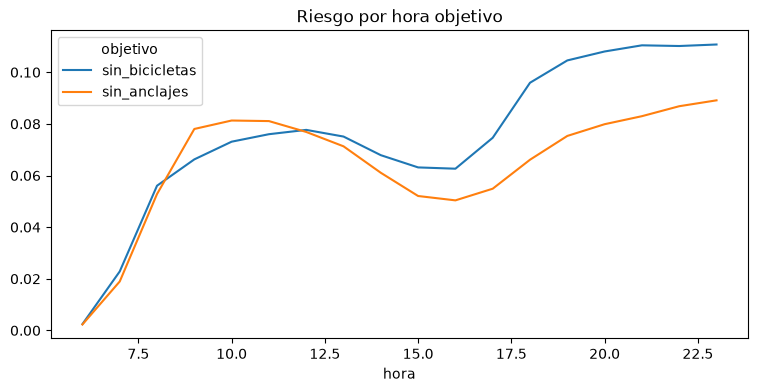

In [4]:
por_hora = pd.crosstab(df["hora"], df["objetivo"], normalize="index")
por_hora[["sin_bicicletas", "sin_anclajes"]].plot(figsize=(9, 4), title="Riesgo por hora objetivo")
plt.show()

## Resultados del experimento (leidos del archivo que escribe train_p2)

In [5]:
res = json.loads((CONFIG.reports_dir / "figures" / "p2_resultados.json").read_text())
filas = []
for nivel, modelos in res["resultados"].items():
    for nombre, m in modelos.items():
        filas.append({"nivel_inicial": nivel, "modelo": nombre,
                      **{k: m.get(k) for k in ["test_macro_f1", "test_recall_sin_bicicletas", "test_recall_sin_anclajes",
                                                "test_precision_sin_bicicletas", "test_precision_sin_anclajes",
                                                "test_pr_auc_sin_bicicletas", "test_pr_auc_sin_anclajes", "test_nuevas_macro_f1"]}})
pd.DataFrame(filas).round(3)

,nivel_inicial,modelo,test_macro_f1,test_recall_sin_bicicletas,test_recall_sin_anclajes,test_precision_sin_bicicletas,test_precision_sin_anclajes,test_pr_auc_sin_bicicletas,test_pr_auc_sin_anclajes,test_nuevas_macro_f1
0,0.5,baseline_mayoritaria,0.315,0.000,0.000,0.000,0.000,NaN,NaN,0.329
1,0.5,baseline_semana_previa,0.572,0.338,0.448,0.338,0.448,NaN,NaN,0.554
2,0.5,baseline_persistencia,0.804,0.696,0.694,0.754,0.745,NaN,NaN,0.825
3,0.5,hgb,0.740,0.942,0.954,0.472,0.499,0.816,0.833,0.744
4,0.5,hgb_sin_pesos,0.822,0.701,0.741,0.775,0.775,0.817,0.834,0.838
5,0.3,baseline_mayoritaria,0.301,0.000,0.000,0.000,0.000,NaN,NaN,0.317
6,0.3,baseline_semana_previa,0.572,0.410,0.435,0.409,0.430,NaN,NaN,0.528
7,0.3,baseline_persistencia,0.808,0.739,0.687,0.787,0.743,NaN,NaN,0.814
8,0.3,hgb,0.760,0.903,0.960,0.626,0.462,0.850,0.826,0.758
9,0.7,baseline_mayoritaria,0.310,0.000,0.000,0.000,0.000,NaN,NaN,0.325


In [6]:
res["params_hgb"], pd.DataFrame(res["rejilla"])

({'learning_rate': 0.1,
  'max_leaf_nodes': 63,
  'max_iter': 300,
  'l2_regularization': 1.0},
    learning_rate  max_leaf_nodes  max_iter  l2_regularization  val_macro_f1
 0           0.10              31       200                0.0      0.748199
 1           0.10              63       300                1.0      0.754427
 2           0.05              63       400                1.0      0.752351)

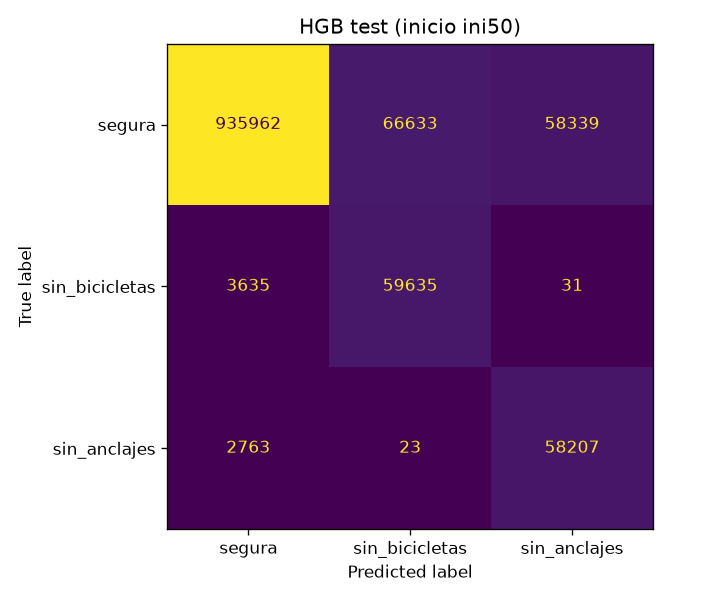

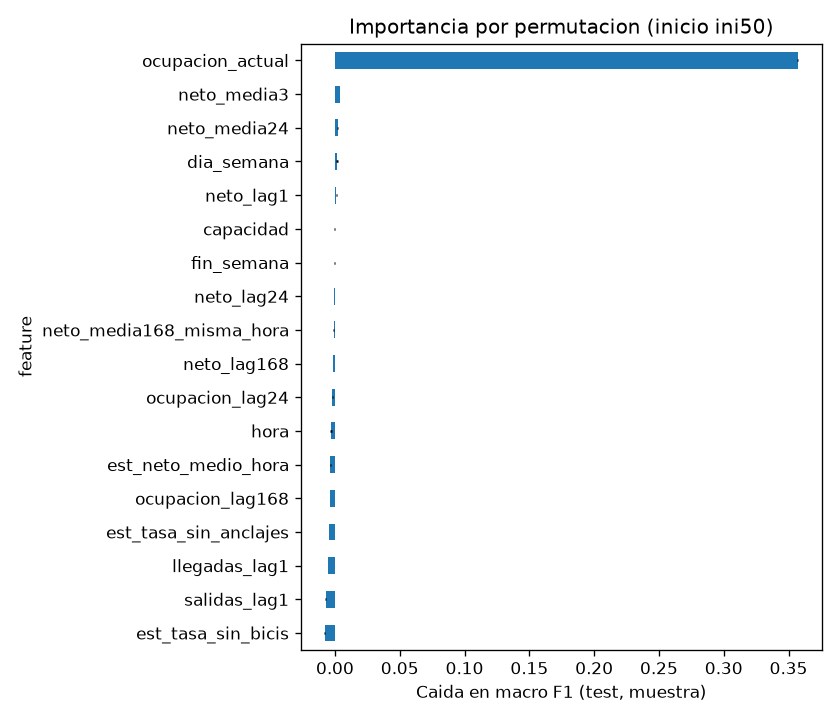

In [7]:
from IPython.display import Image, display
display(Image(str(CONFIG.reports_dir / "figures" / "p2_cm_hgb_ini50.png")))
display(Image(str(CONFIG.reports_dir / "figures" / "p2_importancia_permutacion_ini50.png")))